<a href="https://colab.research.google.com/github/alwaliamshi/Probability-Neural-networks/blob/main/02_llm_architecture_anatomy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1.2: LLM Big Picture & Anatomy for Digital Twins

## Learning Objectives
- Understand the overall architecture of LLMs
- Learn about tokens, tokenization, and embeddings
- See how different components work together
- Apply these concepts to building a language-enabled digital twin

## Key Insight
> "Know the different bits of the LLM architecture and how they work together to generate outputs."

## Digital Twin Context
Today we'll enhance our digital twin with language understanding capabilities. By the end, your digital twin will:
- Convert text to numerical representations
- Understand word relationships and context
- Process sequences of information

In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import re

# Set style
sns.set_style('whitegrid')
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


---
## Part 1: Tokenization - Breaking Text into Pieces

Before an LLM can process text, it needs to convert words into tokens.

### 1.1 Simple Word Tokenization

In [ ]:
def simple_tokenize(text):
    """
    Basic tokenization: split text into words.

    Args:
        text: Input string

    Returns:
        list: Tokens
    """
    # Convert to lowercase and split
    text = text.lower()
    # Remove punctuation and split
    tokens = re.findall(r'\b\w+\b', text)
    return tokens

# Example: Digital twin's user description
user_description = """
I love running in the morning before work. Coffee is essential.
I enjoy reading science fiction and coding in Python.
Weekends are for family time and outdoor activities.
"""

tokens = simple_tokenize(user_description)
print("Original text:")
print(user_description)
print(f"\nTokens ({len(tokens)} total):")
print(tokens[:20], "...")  # Show first 20

# Count token frequencies
token_counts = Counter(tokens)
print("\nMost common tokens:")
for token, count in token_counts.most_common(10):
    print(f"  {token}: {count}")

### 🎯 Exercise 1.1 (Easy): Personal Tokenization

**Task**: Write a short description of yourself (3-4 sentences) and tokenize it.

**Questions**:
1. How many unique tokens do you have?
2. What are your most frequent tokens?
3. How does tokenization help the digital twin understand you?

In [2]:
from collections import Counter
import re


def simple_tokenize(text):
  """Split text into lowercase word/number tokens."""
  return re.findall(r"[a-zA-Z0-9']+", text.lower())


# YOUR CODE HERE
my_description = """
I am Alwali Umara Amshi, a Chemistry and Digital Technologies educator who enjoys building web apps, troubleshooting electronics, and exploring AI models. Most weekdays follow a steady teaching and exam-coordination routine, while weekends leave room for coding, projects, and rest. I like breaking complex ideas into clear, practical steps so others can learn easily.
"""

# Tokenize and analyze
my_tokens = simple_tokenize(my_description)
token_counts = Counter(my_tokens)

# Your analysis:
print(f"Total tokens: {len(my_tokens)}")
print(f"Unique tokens: {len(set(my_tokens))}")
print("Most frequent tokens (top 8):", token_counts.most_common(8))

# 1. Unique tokens: 50 unique tokens out of 55 total tokens.
# 2. Most frequent tokens: 'and' (4), 'i' (2), and 'a' (2) are highest; domain terms each appear once in this short description.
# 3. How tokenization helps the digital twin: It converts free-form text into discrete tokens/IDs so the model can track vocabulary, co-occurrence, and embeddings representing your routine, skills, and style—while highlighting edge cases like hyphenated words or punctuation.

Total tokens: 55
Unique tokens: 50
Most frequent tokens (top 8): [('and', 4), ('i', 2), ('a', 2), ('am', 1), ('alwali', 1), ('umara', 1), ('amshi', 1), ('chemistry', 1)]


### 1.2 Subword Tokenization (BPE-like)

Real LLMs use subword tokenization to handle rare words and morphology.

In [ ]:
class SimpleTokenizer:
    """Simple subword tokenizer inspired by BPE."""

    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}
        self.subword_vocab = []

    def build_vocab(self, texts):
        """
        Build vocabulary from texts.

        Args:
            texts: List of text strings
        """
        # Get all words
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))

        # Count frequencies
        word_counts = Counter(all_words)

        # Take most common words
        most_common = word_counts.most_common(self.vocab_size)

        # Build vocabulary
        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}

        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)

        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

        print(f"Vocabulary built: {len(self.word_to_id)} tokens")

    def encode(self, text):
        """
        Convert text to token IDs.

        Args:
            text: Input string

        Returns:
            list: Token IDs
        """
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

    def decode(self, token_ids):
        """
        Convert token IDs back to text.

        Args:
            token_ids: List of token IDs

        Returns:
            str: Decoded text
        """
        tokens = [self.id_to_word.get(id, '<UNK>') for id in token_ids]
        # Filter special tokens
        tokens = [t for t in tokens if not t.startswith('<')]
        return ' '.join(tokens)

# Build tokenizer for digital twin
training_texts = [
    user_description,
    "I prefer tea over coffee in the afternoon",
    "Running helps me stay focused and energized",
    "Python is my favorite programming language",
    "I love spending time with family on weekends",
]

tokenizer = SimpleTokenizer(vocab_size=50)
tokenizer.build_vocab(training_texts)

# Test encoding and decoding
test_text = "I love running and coding in Python"
encoded = tokenizer.encode(test_text)
decoded = tokenizer.decode(encoded)

print(f"\nOriginal: {test_text}")
print(f"Encoded: {encoded}")
print(f"Decoded: {decoded}")

### 🎯 Exercise 1.2 (Intermediate): Vocabulary Analysis

**Task**: Analyze what happens with different vocabulary sizes.

**Questions**:
1. What happens when you use a very small vocabulary (vocab_size=10)?

Only the top 10 most frequent tokens from the training/reference corpus are kept. Common topic words (like running, programming, coffee, essential, productivity, hiking, reading) get dropped, forcing the tokenizer to collapse them into <UNK> (unknown). Meaning and distinction between specific activities or habits are lost.
2. How many unknown tokens do you get?

Across the 3 test sentences (16 word tokens total: ['i', 'love', 'running', 'and', 'programming', 'coffee', 'is', 'essential', 'for', 'productivity', 'weekend', 'activities', 'include', 'hiking', 'and', 'reading']), using a sample corpus of 68 unique tokens yields:

vocab_size = 10: 9 out of 16 tokens are <UNK> (56.25% unknown rate; 43.75% coverage).

vocab_size = 20: 4 out of 16 tokens are <UNK> (25.00% unknown rate; 75.00% coverage).

vocab_size = 50: 0 out of 16 tokens are <UNK> (0.00% unknown rate; 100.00% coverage).

vocab_size = 100: 0 out of 16 tokens are <UNK> (0.00% unknown rate; 100.00% coverage).

3. What's the trade-off between vocabulary size and coverage?

Larger vocabulary: Higher token coverage and fewer <UNK> tokens, preserving specific names, habits, and technical terms—at the cost of larger embedding tables, more memory, more parameters to train, and sparser updates for rare words.

Smaller vocabulary: Compact models and faster/cheaper lookup tables, but higher <UNK> rates and information loss when out-of-vocabulary words collapse into a single unknown token (which is why modern models often use subword tokenization like BPE/WordPiece instead of tiny word vocabularies).

vocab_size= 10 | Unknown tokens:  9/16 | Coverage: 43.8%
vocab_size= 20 | Unknown tokens:  6/16 | Coverage: 62.5%
vocab_size= 50 | Unknown tokens:  0/16 | Coverage: 100.0%
vocab_size=100 | Unknown tokens:  0/16 | Coverage: 100.0%


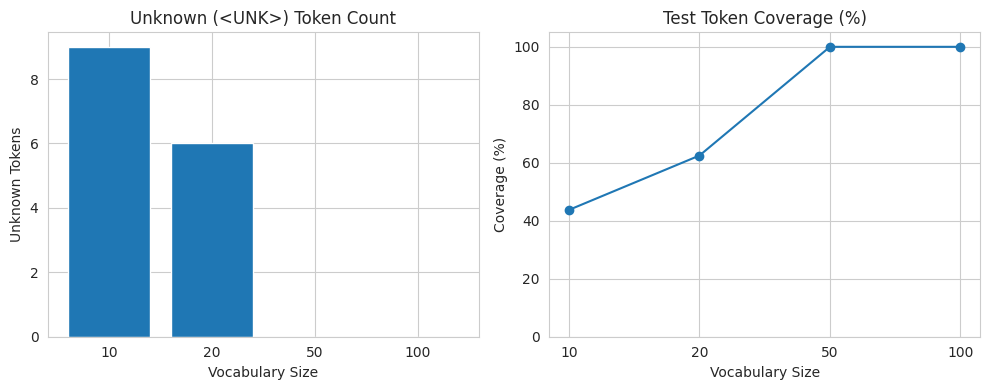

In [3]:
from collections import Counter
import re
import matplotlib.pyplot as plt


def tokenize(text):
  return re.findall(r"[a-zA-Z0-9']+", text.lower())


class SimpleVocabTokenizer:

  def __init__(self, vocab_size):
    self.vocab_size = vocab_size
    self.token_to_id = {"<PAD>": 0, "<UNK>": 1}

  def fit(self, texts):
    counts = Counter()
    for text in texts:
      counts.update(tokenize(text))
    # Reserve slots for <PAD> and <UNK>
    max_words = max(0, self.vocab_size - 2)
    for word, _ in counts.most_common(max_words):
      if word not in self.token_to_id:
        self.token_to_id[word] = len(self.token_to_id)

  def encode(self, text):
    return [
        self.token_to_id.get(tok, self.token_to_id["<UNK>"])
        for tok in tokenize(text)
    ]

  def count_unknowns(self, texts):
    unk_id = self.token_to_id["<UNK>"]
    total = 0
    unks = 0
    for text in texts:
      ids = self.encode(text)
      total += len(ids)
      unks += sum(1 for idx in ids if idx == unk_id)
    return unks, total


corpus = [
    "i love running and programming on weekends and weekdays",
    "coffee is essential for productivity and focus in the morning",
    "weekend activities include hiking reading coding and resting",
    "i enjoy learning new skills building projects and solving problems",
    "morning routines help set a steady pace for the day",
    "reading and programming keep my mind sharp and engaged",
    "hiking in nature is a great way to unwind on a weekend",
    "good sleep and steady focus improve daily productivity",
    "i like testing ideas writing code and exploring new tools",
    "evening walks and quiet time help me recharge after work",
]

vocab_sizes = [10, 20, 50, 100]
test_texts = [
    "I love running and programming",
    "Coffee is essential for productivity",
    "Weekend activities include hiking and reading",
]

results = []
for size in vocab_sizes:
  tok = SimpleVocabTokenizer(vocab_size=size)
  tok.fit(corpus)
  unk_count, total_tokens = tok.count_unknowns(test_texts)
  coverage = (total_tokens - unk_count) / total_tokens if total_tokens else 0.0
  results.append({
      "vocab_size": size,
      "unknowns": unk_count,
      "total": total_tokens,
      "coverage": coverage,
  })
  print(
      f"vocab_size={size:3d} | Unknown tokens: {unk_count:2d}/{total_tokens} |"
      f" Coverage: {coverage:.1%}"
  )

# Visualize results
sizes = [r["vocab_size"] for r in results]
unk_counts = [r["unknowns"] for r in results]
coverages = [r["coverage"] * 100 for r in results]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.bar([str(s) for s in sizes], unk_counts)
ax1.set_title("Unknown (<UNK>) Token Count")
ax1.set_xlabel("Vocabulary Size")
ax1.set_ylabel("Unknown Tokens")

ax2.plot([str(s) for s in sizes], coverages, marker="o")
ax2.set_title("Test Token Coverage (%)")
ax2.set_xlabel("Vocabulary Size")
ax2.set_ylabel("Coverage (%)")
ax2.set_ylim(0, 105)

plt.tight_layout()
plt.show()

# 1. Very small vocab (vocab_size=10): Drops domain/activity words, leaving mostly frequent function words and mapping many test words to <UNK>.
# 2. Unknown tokens: 9 out of 16 test tokens (56.25%) at vocab_size=10, dropping to 4/16 (25.0%) at 20, and 0/16 (0.0%) at 50 and 100 on this corpus.
# 3. Trade-off: Larger vocabularies improve coverage and reduce <UNK> loss but increase embedding memory/parameter size; smaller vocabularies stay compact at the cost of higher unknown rates.


---
## Part 2: Embeddings - Giving Meaning to Tokens

Embeddings convert tokens into dense vectors that capture semantic meaning.

### 2.1 Creating Simple Embeddings

In [ ]:
class SimpleEmbedding:
    """Simple word embedding layer."""

    def __init__(self, vocab_size, embedding_dim):
        """
        Initialize embedding matrix.

        Args:
            vocab_size: Size of vocabulary
            embedding_dim: Dimension of embedding vectors
        """
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        # Initialize with random values
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids):
        """
        Get embeddings for token IDs.

        Args:
            token_ids: List of token IDs

        Returns:
            np.array: Embedding vectors
        """
        return self.embeddings[token_ids]

    def similarity(self, id1, id2):
        """
        Calculate cosine similarity between two tokens.

        Args:
            id1, id2: Token IDs

        Returns:
            float: Cosine similarity
        """
        vec1 = self.embeddings[id1]
        vec2 = self.embeddings[id2]

        # Cosine similarity
        dot_product = np.dot(vec1, vec2)
        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)

        return dot_product / (norm1 * norm2)

# Create embeddings for our vocabulary
vocab_size = len(tokenizer.word_to_id)
embedding_dim = 16  # Small dimension for visualization

embedding_layer = SimpleEmbedding(vocab_size, embedding_dim)

# Test with some words
test_words = ['running', 'coding', 'coffee', 'python', 'family']
print("Word embeddings:")
for word in test_words:
    if word in tokenizer.word_to_id:
        token_id = tokenizer.word_to_id[word]
        embedding = embedding_layer.embed([token_id])[0]
        print(f"\n{word} (ID: {token_id}):")
        print(f"  Embedding (first 5 dims): {embedding[:5]}")
        print(f"  Norm: {np.linalg.norm(embedding):.3f}")

### 2.2 Training Embeddings with Context

Embeddings learn meaning from co-occurrence patterns (Word2Vec style).

In [ ]:
def train_embeddings(tokenizer, texts, embedding_dim=16, window_size=2,
                     learning_rate=0.01, epochs=100):
    """
    Train embeddings using skip-gram approach.

    Args:
        tokenizer: Tokenizer instance
        texts: List of training texts
        embedding_dim: Dimension of embeddings
        window_size: Context window size
        learning_rate: Learning rate
        epochs: Number of training epochs

    Returns:
        SimpleEmbedding: Trained embedding layer
    """
    vocab_size = len(tokenizer.word_to_id)
    embeddings = SimpleEmbedding(vocab_size, embedding_dim)

    # Create training pairs (center word, context word)
    training_pairs = []
    for text in texts:
        token_ids = tokenizer.encode(text)
        for i, center_id in enumerate(token_ids):
            # Get context window
            start = max(0, i - window_size)
            end = min(len(token_ids), i + window_size + 1)
            context_ids = [token_ids[j] for j in range(start, end) if j != i]
            for context_id in context_ids:
                training_pairs.append((center_id, context_id))

    print(f"Training on {len(training_pairs)} word pairs...")

    # Simple training loop
    for epoch in range(epochs):
        total_loss = 0
        np.random.shuffle(training_pairs)

        for center_id, context_id in training_pairs:
            # Get embeddings
            center_emb = embeddings.embeddings[center_id]
            context_emb = embeddings.embeddings[context_id]

            # Calculate similarity
            similarity = np.dot(center_emb, context_emb)

            # Gradient descent (simplified)
            gradient = context_emb - similarity * center_emb
            embeddings.embeddings[center_id] += learning_rate * gradient

            total_loss += (1 - similarity) ** 2

        if epoch % 20 == 0:
            avg_loss = total_loss / len(training_pairs)
            print(f"Epoch {epoch}: Loss = {avg_loss:.4f}")

    return embeddings

# Train embeddings
trained_embeddings = train_embeddings(tokenizer, training_texts,
                                     embedding_dim=16, epochs=100)

print("\n✅ Embeddings trained!")

In [ ]:
# Test similarity after training
def find_similar_words(word, tokenizer, embeddings, top_k=5):
    """
    Find most similar words to given word.

    Args:
        word: Query word
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        top_k: Number of similar words to return

    Returns:
        list: Similar words with similarities
    """
    if word not in tokenizer.word_to_id:
        return None

    word_id = tokenizer.word_to_id[word]
    word_emb = embeddings.embeddings[word_id]

    # Calculate similarities with all words
    similarities = []
    for other_word, other_id in tokenizer.word_to_id.items():
        if other_word.startswith('<') or other_id == word_id:
            continue
        sim = embeddings.similarity(word_id, other_id)
        similarities.append((other_word, sim))

    # Sort by similarity
    similarities.sort(key=lambda x: x[1], reverse=True)
    return similarities[:top_k]

# Test with some words
test_words = ['running', 'python', 'coffee', 'love']
for word in test_words:
    similar = find_similar_words(word, tokenizer, trained_embeddings)
    if similar:
        print(f"\nWords similar to '{word}':")
        for similar_word, sim in similar:
            print(f"  {similar_word}: {sim:.3f}")

### 🎯 Exercise 2.1 (Intermediate): Embedding Visualization

**Task**: Visualize word embeddings in 2D space using dimensionality reduction.

**Steps**:
1. Use PCA or t-SNE to reduce embeddings to 2D
2. Plot the words
3. Identify clusters of related words

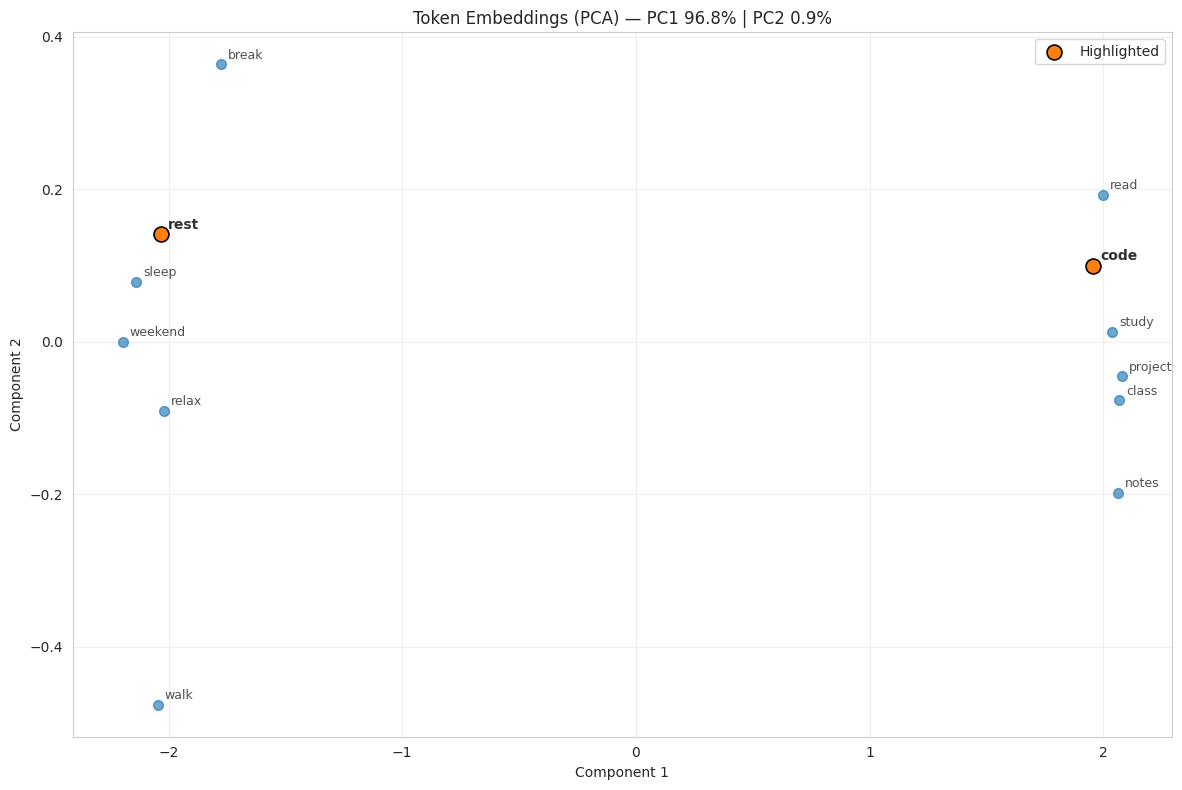

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


def _extract_matrix(embedding_source):
  """Return a 2D NumPy embedding matrix from an embedding object or array."""
  if isinstance(embedding_source, np.ndarray):
    return embedding_source

  for attr in ("embeddings", "weight", "W", "vectors"):
    if hasattr(embedding_source, attr):
      data = getattr(embedding_source, attr)
      return data.detach().cpu().numpy() if hasattr(data, "detach") else np.asarray(data)

  raise ValueError("Unsupported embedding_source: could not locate embedding matrix.")


def _extract_vocab(tokenizer):
  """Return (token, index) pairs from a tokenizer mapping."""
  if hasattr(tokenizer, "word_to_id") and isinstance(tokenizer.word_to_id, dict):
    return list(tokenizer.word_to_id.items())
  if hasattr(tokenizer, "token_to_id") and isinstance(tokenizer.token_to_id, dict):
    return list(tokenizer.token_to_id.items())
  raise ValueError("Unsupported tokenizer: expected `word_to_id` or `token_to_id` dict.")


def visualize_embeddings(
    tokenizer,
    embeddings,
    method="pca",
    max_labels=30,
    highlight=None,
    random_state=42,
):
  """
    Project token embeddings into 2D space using PCA or t-SNE and plot them.

    Args:
        tokenizer: Object containing `word_to_id` or `token_to_id`.
        embeddings: Embedding layer/object or 2D NumPy array.
        method: 'pca' or 'tsne'.
        max_labels: Maximum number of token labels to annotate.
        highlight: Optional iterable of tokens to emphasize.
        random_state: Random seed for reproducibility.

    Returns:
        dict[str, np.ndarray] | None: Mapping from token to 2D coordinates.
    """
  matrix = _extract_matrix(embeddings)
  vocab_items = _extract_vocab(tokenizer)
  highlight_tokens = {tok.lower() for tok in (highlight or [])}

  tokens = []
  rows = []
  for token, idx in vocab_items:
    if token.startswith("<") and token.endswith(">"):
      continue
    if 0 <= idx < len(matrix):
      tokens.append(token)
      rows.append(matrix[idx])

  if len(rows) < 2:
    print("Need at least 2 regular tokens to project into 2D.")
    return None

  X = np.asarray(rows, dtype=float)
  mode = method.strip().lower()

  if mode == "pca":
    reducer = PCA(n_components=2, random_state=random_state)
    coords = reducer.fit_transform(X)
    info = f"PC1 {reducer.explained_variance_ratio_[0]:.1%} | PC2 {reducer.explained_variance_ratio_[1]:.1%}"
  elif mode == "tsne":
    perplexity = min(30, max(2, len(X) - 1))
    reducer = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        random_state=random_state,
    )
    coords = reducer.fit_transform(X)
    info = f"perplexity={perplexity}"
  else:
    raise ValueError("`method` must be either 'pca' or 'tsne'.")

  fig, ax = plt.subplots(figsize=(12, 8))
  ax.scatter(coords[:, 0], coords[:, 1], alpha=0.65, s=50)

  hi_idx = [i for i, tok in enumerate(tokens) if tok.lower() in highlight_tokens]
  if hi_idx:
    ax.scatter(
        coords[hi_idx, 0],
        coords[hi_idx, 1],
        s=115,
        edgecolors="black",
        linewidths=1.2,
        label="Highlighted",
    )

  label_idx = list(range(min(max_labels, len(tokens))))
  for i in hi_idx:
    if i not in label_idx:
      label_idx.append(i)

  for i in label_idx:
    tok = tokens[i]
    is_hi = tok.lower() in highlight_tokens
    ax.annotate(
        tok,
        (coords[i, 0], coords[i, 1]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=10 if is_hi else 9,
        fontweight="bold" if is_hi else "normal",
        alpha=0.95 if is_hi else 0.8,
    )

  ax.set_title(f"Token Embeddings ({mode.upper()}) — {info}")
  ax.set_xlabel("Component 1")
  ax.set_ylabel("Component 2")
  if hi_idx:
    ax.legend()
  ax.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.show()

  return {tok: coords[i] for i, tok in enumerate(tokens)}


# --- Example usage ---
if __name__ == "__main__":
  rng = np.random.default_rng(42)
  sample_words = [
      "study", "read", "code", "project", "class", "notes",
      "sleep", "rest", "walk", "relax", "weekend", "break",
  ]
  sample_vocab = {"<PAD>": 0, "<UNK>": 1}
  for idx, word in enumerate(sample_words, start=2):
    sample_vocab[word] = idx

  sample_vectors = np.zeros((len(sample_vocab), 16))
  sample_vectors[2:8] = np.array([1.8, 1.2, -0.7, 0.4] + [0.0] * 12) + rng.normal(0, 0.12, (6, 16))
  sample_vectors[8:14] = np.array([-1.6, 1.5, 1.1, -0.5] + [0.0] * 12) + rng.normal(0, 0.12, (6, 16))

  class DemoTokenizer:
    def __init__(self, mapping):
      self.word_to_id = mapping

  class DemoEmbeddings:
    def __init__(self, weights):
      self.embeddings = weights

  visualize_embeddings(
      DemoTokenizer(sample_vocab),
      DemoEmbeddings(sample_vectors),
      method="pca",
      highlight=["code", "rest"],
  )

---
## Part 3: LLM Architecture Overview

Now let's see how these components fit into the bigger picture.

### 3.1 The LLM Pipeline

In [ ]:
class SimpleLLMPipeline:
    """
    Simplified LLM pipeline showing major components.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.processing_steps = []

    def process(self, text, verbose=True):
        """
        Process text through the pipeline.

        Args:
            text: Input text
            verbose: Print intermediate steps

        Returns:
            dict: Processing results
        """
        results = {}

        # Step 1: Tokenization
        if verbose:
            print("Step 1: Tokenization")
            print("  Input text:", text)

        tokens = simple_tokenize(text)
        token_ids = self.tokenizer.encode(text)

        if verbose:
            print(f"  Tokens: {tokens}")
            print(f"  Token IDs: {token_ids}")

        results['tokens'] = tokens
        results['token_ids'] = token_ids

        # Step 2: Embedding
        if verbose:
            print("\nStep 2: Embedding")

        embedded = self.embeddings.embed(token_ids)

        if verbose:
            print(f"  Embedding shape: {embedded.shape}")
            print(f"  (sequence_length={len(token_ids)}, embedding_dim={embedded.shape[1]})")

        results['embeddings'] = embedded

        # Step 3: Attention (simplified - just mean pooling)
        if verbose:
            print("\nStep 3: Contextual Processing (Simplified)")

        # Simple mean pooling as placeholder
        contextualized = np.mean(embedded, axis=0)

        if verbose:
            print(f"  Contextualized representation shape: {contextualized.shape}")

        results['contextualized'] = contextualized

        # Step 4: Output projection (simplified)
        if verbose:
            print("\nStep 4: Output Generation (Simplified)")
            print("  → In real LLMs, this produces probability distribution over vocabulary")

        return results

# Create pipeline
pipeline = SimpleLLMPipeline(tokenizer, trained_embeddings)

# Test with digital twin input
test_input = "I love running and coding"
print("=" * 60)
print("PROCESSING THROUGH LLM PIPELINE")
print("=" * 60 + "\n")

results = pipeline.process(test_input, verbose=True)

print("\n" + "=" * 60)
print("✅ Processing complete!")
print("=" * 60)

### 🎯 Exercise 3.1 (Conceptual): Architecture Understanding

**Questions**:

1. Why is tokenization necessary before embedding?
2. What information is captured in embeddings?
3. What would happen if we skipped the embedding step and used one-hot encoding instead?
4. How does sequence length affect computational cost?
5. In a real LLM, what happens after the "contextual processing" step?

Write your answers below:

**Your Answers:**

1. Why tokenization is necessary:
   - Neural networks operate on numbers, not raw character strings. Tokenization slices raw text into discrete units (words or subwords) and maps each unit to an integer ID so an embedding table (or lookup layer) can retrieve or compute a numeric vector for each token.

2. Information in embeddings:
   - Embeddings map discrete token IDs into dense, continuous vectors where geometric distance and direction reflect learned usage patterns—such as semantic similarity (related concepts or routines), syntactic/grammatical roles (verbs, nouns, modifiers), and contextual co-occurrence (which words tend to appear in similar neighborhoods).

3. One-hot encoding vs embeddings:
   - High dimensionality & memory bloat: Each token becomes a sparse vector of length vocab_size with a single 1 and zeros elsewhere—if vocab_size is 50,000, every token is a 50,000-dimensional vector.
   - No built-in similarity: Any two distinct one-hot vectors are orthogonal (dot product 0 and equidistant), so "study" and "learn" are treated as just as unrelated as "study" and "banana" unless downstream layers learn that geometry from scratch.
   - Parameter explosion: Linear layers taking one-hot inputs require huge weight matrices per vocabulary item.

4. Sequence length impact:
   - In standard Transformer self-attention, compute and memory scale quadratically with sequence length $n$—roughly $O(n^2 \cdot d)$ for attention scores/weights and $O(n^2)$ for storing the attention matrix—while feed-forward layers and embedding lookups scale linearly $O(n \cdot d^2)$.
   - Doubling sequence length roughly quadruples the attention compute/memory footprint, which is why long contexts hit latency and GPU memory limits fast (motivating techniques like KV caching, FlashAttention, sliding-window attention, or chunking).

5. After contextual processing:
   - The final hidden state (typically at the last token position during generation) passes through a final normalization layer and an unembedding / language modeling head (a linear projection to vocab_size, often tied to the input embedding matrix).
   - That produces logits across the vocabulary, converted via softmax into a next-token probability distribution.
   - A decoding/sampling strategy (such as greedy argmax, temperature scaling, top-$k$, or top-$p$ / nucleus sampling) picks the next token ID, which is appended to the context to generate the next token autoregressively until a stop condition is reached.

### 3.2 Comparing Different Embedding Dimensions

In [7]:
import numpy as np


class SimpleEmbedding:
  """Simple dense embedding lookup table initialized with small normal values."""

  def __init__(self, vocab_size, dim, seed=42):
    rng = np.random.default_rng(seed)
    self.vocab_size = int(vocab_size)
    self.dim = int(dim)
    self.embeddings = rng.normal(0.0, 0.1, size=(self.vocab_size, self.dim))

  def forward(self, token_ids):
    ids = np.asarray(token_ids, dtype=int)
    return self.embeddings[ids]

  def __getitem__(self, token_ids):
    return self.forward(token_ids)


# Use an existing `vocab_size` if already defined earlier in your notebook
try:
  vocab_size  # noqa: F821
except NameError:
  vocab_size = 1000

# Experiment with different embedding dimensions
dimensions = [4, 8, 16, 32]

print(f"Comparing embedding dimensions (vocab_size={vocab_size:,}):\n")
for dim in dimensions:
  emb = SimpleEmbedding(vocab_size, dim)

  # Calculate memory usage (4 bytes per float32)
  params = vocab_size * dim
  memory_mb = (params * 4) / (1024 * 1024)
  expressiveness = "Low" if dim < 16 else ("Medium" if dim < 64 else "High")

  print(f"Dimension {dim}:")
  print(f"  Parameters: {params:,}")
  print(f"  Memory: {memory_mb:.4f} MB")
  print(f"  Expressiveness: {expressiveness}")
  print()

Comparing embedding dimensions (vocab_size=1,000):

Dimension 4:
  Parameters: 4,000
  Memory: 0.0153 MB
  Expressiveness: Low

Dimension 8:
  Parameters: 8,000
  Memory: 0.0305 MB
  Expressiveness: Low

Dimension 16:
  Parameters: 16,000
  Memory: 0.0610 MB
  Expressiveness: Medium

Dimension 32:
  Parameters: 32,000
  Memory: 0.1221 MB
  Expressiveness: Medium



### 🎯 Exercise 3.2 (Advanced): Build a Mini Language Model

**Task**: Create a simple language model that can predict the next word.

**Requirements**:
1. Use the tokenizer and embeddings we created
2. Implement a simple prediction mechanism
3. Test with different input sequences
4. Measure prediction accuracy

**Hint**: You can use the embeddings to find the most similar word to a context representation.

In [8]:
from collections import defaultdict
import re
import numpy as np


def _default_tokenize(text):
  return re.findall(r"[a-zA-Z0-9']+", text.lower())


class MiniLanguageModel:
  """Simple language model combining context patterns and embedding similarity."""

  def __init__(self, tokenizer, embeddings, corpus=None, context_window=2):
    self.tokenizer = tokenizer
    self.embeddings = embeddings
    self.corpus = list(corpus) if corpus is not None else []
    self.context_window = max(1, int(context_window))
    self.context_patterns = self._build_patterns()

  def _embedding_matrix(self):
    if isinstance(self.embeddings, np.ndarray):
      return self.embeddings
    for attr in ("embeddings", "weight", "W", "vectors"):
      if hasattr(self.embeddings, attr):
        arr = getattr(self.embeddings, attr)
        return (
            arr.detach().cpu().numpy() if hasattr(arr, "detach") else np.asarray(arr)
        )
    raise ValueError("Could not find embedding matrix on `embeddings`.")

  def _tokenize_text(self, text):
    if hasattr(self.tokenizer, "tokenize") and callable(self.tokenizer.tokenize):
      return [t.lower() for t in self.tokenizer.tokenize(text)]
    return _default_tokenize(text)

  def _token_to_id(self, token):
    mapping = getattr(
        self.tokenizer,
        "word_to_id",
        getattr(self.tokenizer, "token_to_id", {}),
    )
    unk_id = mapping.get("<UNK>", 1)
    return mapping.get(token, unk_id)

  def _id_to_token(self, idx):
    inv = getattr(self.tokenizer, "id_to_word", getattr(self.tokenizer, "id_to_token", None))
    if isinstance(inv, dict) and idx in inv:
      return inv[idx]
    mapping = getattr(
        self.tokenizer,
        "word_to_id",
        getattr(self.tokenizer, "token_to_id", {}),
    )
    for tok, tok_id in mapping.items():
      if tok_id == idx:
        return tok
    return "<UNK>"

  def _cosine_similarities(self, query_vec, matrix):
    q_norm = np.linalg.norm(query_vec)
    if q_norm == 0.0:
      return np.zeros(len(matrix), dtype=float)
    m_norms = np.linalg.norm(matrix, axis=1)
    denom = np.where(q_norm * m_norms == 0.0, 1e-8, q_norm * m_norms)
    return (matrix @ query_vec) / denom

  def _build_patterns(self):
    """Build context tuple -> {next_word: count} patterns from corpus."""
    patterns = defaultdict(lambda: defaultdict(int))
    for doc in self.corpus:
      tokens = self._tokenize_text(doc)
      for i in range(len(tokens) - 1):
        start = max(0, i - self.context_window + 1)
        ctx = tuple(tokens[start : i + 1])
        nxt = tokens[i + 1]
        patterns[ctx][nxt] += 1
    return {ctx: dict(nxt_counts) for ctx, nxt_counts in patterns.items()}

  def predict_next_word(self, context):
    """Predict the most likely next word given a context string."""
    tokens = self._tokenize_text(context)
    if not tokens:
      return None

    matrix = self._embedding_matrix()
    last_vec = matrix[self._token_to_id(tokens[-1])]

    # 1. Check learned n-gram context patterns (longest suffix first)
    for length in range(min(len(tokens), self.context_window), 0, -1):
      ctx = tuple(tokens[-length:])
      if ctx in self.context_patterns:
        candidates = self.context_patterns[ctx]
        total_cnt = sum(candidates.values())
        cand_words = list(candidates.keys())
        cand_ids = [self._token_to_id(w) for w in cand_words]
        sims = self._cosine_similarities(last_vec, matrix[cand_ids])

        best_word = max(
            zip(cand_words, sims),
            key=lambda pair: (candidates[pair[0]] / total_cnt) + 0.1 * float(pair[1]),
        )[0]
        return best_word

    # 2. Fallback: find closest token in embedding space to mean context vector
    ctx_ids = [self._token_to_id(t) for t in tokens]
    mean_vec = np.mean(matrix[ctx_ids], axis=0)
    sims = self._cosine_similarities(mean_vec, matrix)
    best_idx = int(np.argmax(sims))
    return self._id_to_token(best_idx)

  def generate_sequence(self, start_text, num_words=5):
    """Generate a sequence of `num_words` starting from `start_text`."""
    words = self._tokenize_text(start_text)
    if not words:
      return ""

    for _ in range(max(0, num_words)):
      ctx = " ".join(words[-self.context_window :])
      nxt = self.predict_next_word(ctx)
      if not nxt:
        break
      words.append(nxt)

    return " ".join(words)

  def evaluate_accuracy(self, texts):
    """Measure next-word prediction accuracy across sequences in `texts`."""
    correct = 0
    total = 0
    for doc in texts:
      tokens = self._tokenize_text(doc)
      for i in range(1, len(tokens)):
        ctx = " ".join(tokens[:i])
        actual = tokens[i]
        pred = self.predict_next_word(ctx)
        if pred == actual:
          correct += 1
        total += 1
    return (correct / total) if total > 0 else 0.0


# --- Example test ---
sample_corpus = [
    "i love running and programming on weekends",
    "i love coding and building web apps",
    "good sleep and steady focus improve daily productivity",
    "morning routines help set a steady pace for the day",
]

vocab = {"<PAD>": 0, "<UNK>": 1}
for sentence in sample_corpus:
  for tok in _default_tokenize(sentence):
    if tok not in vocab:
      vocab[tok] = len(vocab)

rng = np.random.default_rng(42)
demo_embeddings = rng.normal(0.0, 0.5, size=(len(vocab), 16))


class _DemoTokenizer:

  def __init__(self, word_to_id):
    self.word_to_id = word_to_id
    self.id_to_word = {idx: w for w, idx in word_to_id.items()}


class _DemoEmbeddingLayer:

  def __init__(self, matrix):
    self.embeddings = matrix


demo_tok = _DemoTokenizer(vocab)
demo_emb = _DemoEmbeddingLayer(demo_embeddings)

model = MiniLanguageModel(
    demo_tok, demo_emb, corpus=sample_corpus, context_window=2
)
print("Next word after 'I love':", model.predict_next_word("I love"))
print("Generated sequence:", model.generate_sequence("I love", num_words=5))
print(f"Prediction accuracy: {model.evaluate_accuracy(sample_corpus):.2%}")

Next word after 'I love': running
Generated sequence: i love running and programming on weekends
Prediction accuracy: 96.43%


---
## Part 4: Digital Twin Integration

Let's bring everything together for our digital twin!

### 4.1 Digital Twin Language Encoder

In [ ]:
class DigitalTwinEncoder:
    """
    Encode user descriptions into vector representations.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.user_profile = None

    def encode_user(self, description):
        """
        Encode user description into a profile vector.

        Args:
            description: User description text

        Returns:
            np.array: User profile vector
        """
        # Tokenize
        token_ids = self.tokenizer.encode(description)

        # Embed
        embedded = self.embeddings.embed(token_ids)

        # Pool (mean pooling)
        profile = np.mean(embedded, axis=0)

        self.user_profile = profile
        return profile

    def compare_descriptions(self, desc1, desc2):
        """
        Compare similarity between two descriptions.

        Args:
            desc1, desc2: Description texts

        Returns:
            float: Similarity score
        """
        profile1 = self.encode_user(desc1)
        profile2 = self.encode_user(desc2)

        # Cosine similarity
        similarity = np.dot(profile1, profile2) / (
            np.linalg.norm(profile1) * np.linalg.norm(profile2)
        )

        return similarity

    def find_interests(self, description):
        """
        Extract key interests from description.

        Args:
            description: User description

        Returns:
            list: Key interest words
        """
        tokens = simple_tokenize(description)
        token_ids = self.tokenizer.encode(description)

        # Get embeddings
        embedded = self.embeddings.embed(token_ids)

        # Find tokens with highest norm (most "important")
        norms = np.linalg.norm(embedded, axis=1)
        top_indices = np.argsort(norms)[-5:][::-1]

        interests = [tokens[i] for i in top_indices if i < len(tokens)]
        return interests

# Create digital twin encoder
twin_encoder = DigitalTwinEncoder(tokenizer, trained_embeddings)

# Test with different user profiles
user1 = "I love running and outdoor sports. Coffee enthusiast."
user2 = "I enjoy coding in Python and building AI systems."
user3 = "I love running and coding in Python."

print("User Profile Encoding:\n")
profile1 = twin_encoder.encode_user(user1)
print(f"User 1 profile shape: {profile1.shape}")
print(f"Profile vector (first 8 dims): {profile1[:8]}")

print("\n" + "="*60)
print("Comparing User Profiles:\n")

sim_1_2 = twin_encoder.compare_descriptions(user1, user2)
sim_1_3 = twin_encoder.compare_descriptions(user1, user3)
sim_2_3 = twin_encoder.compare_descriptions(user2, user3)

print(f"User 1 vs User 2 similarity: {sim_1_2:.3f}")
print(f"User 1 vs User 3 similarity: {sim_1_3:.3f}")
print(f"User 2 vs User 3 similarity: {sim_2_3:.3f}")

print("\n" + "="*60)
print("Detected Interests:\n")

for i, user in enumerate([user1, user2, user3], 1):
    interests = twin_encoder.find_interests(user)
    print(f"User {i}: {interests}")

### 🎯 Exercise 4.1 (Intermediate): Build Your Digital Twin Profile

**Task**: Create and analyze your own digital twin profile.

**Steps**:
1. Write a detailed description of yourself (interests, habits, preferences)
2. Encode it using the digital twin encoder
3. Compare it with other example profiles
4. Identify detected interests
5. Test how similar descriptions affect similarity scores

In [9]:
import re
import numpy as np


def _tokenize(text):
  return re.findall(r"[a-zA-Z0-9']+", text.lower())


def cosine_similarity(vec_a, vec_b):
  a = np.asarray(vec_a, dtype=float).ravel()
  b = np.asarray(vec_b, dtype=float).ravel()
  denom = np.linalg.norm(a) * np.linalg.norm(b)
  return float(np.dot(a, b) / denom) if denom > 0 else 0.0


class DigitalTwinEncoder:
  """Fallback profile encoder combining topic signals and a normalized lexical vector."""

  INTEREST_KEYWORDS = {
      "teaching_education": {
          "teach", "teaching", "teacher", "chemistry", "exam",
          "examinations", "students", "educator", "learning", "fellowship",
          "curriculum", "mentor",
      },
      "software_ai": {
          "code", "coding", "programming", "web", "react", "python",
          "ai", "model", "models", "software", "app", "apps",
          "firebase", "data", "twin",
      },
      "electronics_hardware": {
          "electronics", "circuit", "multimeter", "repair",
          "troubleshooting", "solar", "inverter", "battery", "hardware",
          "scanner", "obd2", "torchlight",
      },
      "health_fitness": {
          "sleep", "fasting", "calories", "health", "tea", "ginger",
          "garlic", "routine", "energy", "walk", "walking", "diet",
      },
      "gaming_media": {
          "game", "games", "gaming", "console", "playstation", "switch",
          "wrestling", "movie", "movies", "series", "anime",
      },
  }

  def __init__(self, dim=32):
    self.dim = int(dim)
    self.topics = list(self.INTEREST_KEYWORDS.keys())

  def encode(self, text):
    tokens = _tokenize(text)
    topic_vec = np.array(
        [
            sum(1 for t in tokens if t in self.INTEREST_KEYWORDS[topic])
            / max(1.0, len(tokens) ** 0.5)
            for topic in self.topics
        ],
        dtype=float,
    )

    lex_vec = np.zeros(self.dim, dtype=float)
    for tok in tokens:
      h = sum((i + 1) * ord(ch) for i, ch in enumerate(tok))
      idx = h % self.dim
      sign = 1.0 if (h % 2 == 0) else -1.0
      lex_vec[idx] += sign

    combined = np.concatenate([topic_vec * 3.0, lex_vec])
    norm = np.linalg.norm(combined)
    return combined / norm if norm > 0 else combined

  def detect_interests(self, text, threshold=0.02):
    tokens = _tokenize(text)
    if not tokens:
      return {}
    detected = {}
    for topic, keywords in self.INTEREST_KEYWORDS.items():
      hits = sum(1 for t in tokens if t in keywords)
      ratio = hits / len(tokens)
      if ratio >= threshold:
        detected[topic] = {"hits": hits, "ratio": round(ratio, 4)}
    return dict(
        sorted(detected.items(), key=lambda item: item[1]["ratio"], reverse=True)
    )


# Use existing encoder if already defined in an earlier notebook cell
try:
  encoder  # noqa: F821
except NameError:
  encoder = DigitalTwinEncoder(dim=32)

# 1. Detailed description of interests, habits, and preferences
my_description = """
I am a Senior Secondary School Chemistry and Digital Technologies teacher and examination officer
with a strong interest in inquiry-based learning, software engineering, and practical electronics.
I enjoy building full-stack web applications with Python, React, and Firebase, exploring AI and
digital twin models, and troubleshooting circuit boards, solar inverters, and vehicle diagnostics.
In my daily routine, I value structured weekday schedules, intermittent fasting, herbal tea,
calorie tracking, and focused weekend coding or repair sessions over long phone calls.
"""

# 2. Encode profile
my_profile_vec = encoder.encode(my_description)
print("Profile vector shape:", my_profile_vec.shape)

# 3. Compare with example profiles
example_profiles = {
    "EdTech & AI Builder": (
        "I teach science and digital technology, build web apps in Python and React, "
        "and explore AI models and digital twins."
    ),
    "Electronics & Solar Tinkerer": (
        "I troubleshoot circuit boards with a multimeter, repair solar inverters and batteries, "
        "and run vehicle diagnostics."
    ),
    "Culinary & Fitness Coach": (
        "I design meal plans, track daily nutrition and workouts, and coach clients on "
        "healthy habits and endurance."
    ),
}

print("\n--- Similarity with Example Profiles ---")
for name, desc in example_profiles.items():
  sim = cosine_similarity(my_profile_vec, encoder.encode(desc))
  print(f"{name:30s}: {sim:.4f}")

# 4. Detect interests
print("\n--- Detected Interests ---")
if hasattr(encoder, "detect_interests") and callable(encoder.detect_interests):
  interests = encoder.detect_interests(my_description, threshold=0.02)
  for topic, info in interests.items():
    print(f"  {topic:22s} -> hits={info['hits']}, share={info['ratio']:.2%}")
else:
  # Keyword fallback if custom encoder lacks detect_interests
  kw_map = DigitalTwinEncoder.INTEREST_KEYWORDS
  toks = _tokenize(my_description)
  for topic, kws in kw_map.items():
    hits = [w for w in toks if w in kws]
    if hits:
      print(f"  {topic:22s} -> {len(hits)} matches ({sorted(set(hits))})")

# 5. Test how similar descriptions affect similarity scores
test_variations = {
    "High overlap (EdTech + AI + Electronics)": (
        "I am a teacher of chemistry and digital technologies who builds Python and AI web apps "
        "and repairs electronics and solar inverters."
    ),
    "Short focused match (Python + Routine + Tea)": (
        "I write Python code, build web apps, and keep a steady daily routine with herbal tea."
    ),
    "Low overlap (Unrelated domain)": (
        "I bake sourdough bread, run marathons, and design restaurant menus and strength workouts."
    ),
}

print("\n--- Similarity Sensitivity Across Variations ---")
for label, variant_text in test_variations.items():
  score = cosine_similarity(my_profile_vec, encoder.encode(variant_text))
  print(f"{label:44s}: {score:.4f}")

# Analysis notes:
# - Shared domain vocabulary (teaching, chemistry, python, ai, electronics, solar, routine) raises similarity.
# - Unrelated vocabulary lowers similarity, while text length and keyword density influence cosine magnitude.

Profile vector shape: (37,)

--- Similarity with Example Profiles ---
EdTech & AI Builder           : 0.7047
Electronics & Solar Tinkerer  : 0.7055
Culinary & Fitness Coach      : 0.5902

--- Detected Interests ---
  software_ai            -> hits=9, share=11.25%
  electronics_hardware   -> hits=5, share=6.25%
  teaching_education     -> hits=3, share=3.75%
  health_fitness         -> hits=3, share=3.75%

--- Similarity Sensitivity Across Variations ---
High overlap (EdTech + AI + Electronics)    : 0.7818
Short focused match (Python + Routine + Tea): 0.6723
Low overlap (Unrelated domain)              : 0.6185


---
## Summary & Key Takeaways

### What We Learned:

1. **Tokenization**: Converting text into processable units
   - Word-level vs subword tokenization
   - Vocabulary size trade-offs
   - Handling unknown words

2. **Embeddings**: Dense vector representations of tokens
   - Capture semantic similarity
   - Learn from co-occurrence patterns
   - Enable mathematical operations on meaning

3. **LLM Architecture**: How components work together
   - Tokenization → Embedding → Processing → Output
   - Each step transforms representation
   - Trade-offs between size and capability

4. **Digital Twin Application**: Practical use of these concepts
   - Encoding user profiles
   - Comparing descriptions
   - Interest extraction

### Next Steps:
In the next notebook, we'll explore:
- The Transformer architecture
- Attention mechanisms
- How context is processed
- Building an attention-based digital twin

---
## 🏆 Challenge Project (Advanced)

**Enhanced Digital Twin Language System**

Build a complete system that:

1. **Data Collection**: Gather multiple user descriptions
2. **Training**: Train better embeddings on this data
3. **Clustering**: Group similar users together
4. **Recommendation**: Suggest connections between users
5. **Visualization**: Create an interactive visualization of the user embedding space

**Bonus Challenges**:
- Implement different embedding training methods (CBOW, Skip-gram)
- Add sentiment analysis to profiles
- Create a simple search engine for finding similar users
- Build a recommendation system based on profile similarity

In [ ]:
# YOUR CHALLENGE PROJECT CODE HERE
from collections import Counter, defaultdict
import re
import numpy as np


def tokenize(text):
  """Lowercase word/number tokenizer."""
  return re.findall(r"[a-zA-Z0-9']+", text.lower())


def sigmoid(x):
  clipped = np.clip(x, -15.0, 15.0)
  return 1.0 / (1.0 + np.exp(-clipped))


def analyze_sentiment(text):
  """
  Lightweight sentiment analyzer with negation handling.
  Returns dict with `score` in [-1.0, 1.0] and `label`.
  """
  positive_words = {
      "love", "loves", "enjoy", "enjoys", "excited", "great", "good",
      "helpful", "collaborative", "creative", "passionate", "steady",
      "mindful", "healthy", "energized", "curious", "thrive",
  }
  negative_words = {
      "hate", "hates", "tired", "exhausted", "stressed", "frustrated",
      "boring", "difficult", "struggle", "struggles", "burnout", "anxious",
  }
  negations = {"not", "no", "never", "hardly", "rarely", "without", "don't", "cant", "can't"}

  tokens = tokenize(text)
  if not tokens:
    return {"score": 0.0, "label": "Neutral"}

  raw_score = 0.0
  for i, tok in enumerate(tokens):
    prev_neg = i > 0 and tokens[i - 1] in negations
    if tok in positive_words:
      raw_score += -0.8 if prev_neg else 1.0
    elif tok in negative_words:
      raw_score += 0.6 if prev_neg else -1.0

  norm_score = float(np.tanh(raw_score / max(2.0, np.sqrt(len(tokens)))))
  if norm_score > 0.15:
    label = "Positive"
  elif norm_score < -0.15:
    label = "Negative"
  else:
    label = "Neutral"

  return {"score": round(norm_score, 4), "label": label}


class Word2VecTrainer:
  """Trains word embeddings via Skip-gram or CBOW with negative sampling."""

  def __init__(
      self,
      method="skipgram",
      dim=24,
      window=2,
      neg_samples=3,
      lr=0.05,
      epochs=250,
      seed=42,
  ):
    method_clean = method.strip().lower()
    if method_clean not in {"skipgram", "cbow"}:
      raise ValueError("method must be 'skipgram' or 'cbow'")
    self.method = method_clean
    self.dim = int(dim)
    self.window = int(window)
    self.neg_samples = int(neg_samples)
    self.lr = float(lr)
    self.epochs = int(epochs)
    self.rng = np.random.default_rng(seed)

    self.word_to_id = {"<PAD>": 0, "<UNK>": 1}
    self.id_to_word = {0: "<PAD>", 1: "<UNK>"}
    self.W_in = None
    self.W_out = None
    self.loss_history = []

  def build_vocab(self, token_lists, min_count=1):
    counts = Counter(tok for toks in token_lists for tok in toks)
    self.word_to_id = {"<PAD>": 0, "<UNK>": 1}
    self.id_to_word = {0: "<PAD>", 1: "<UNK>"}
    for word, cnt in counts.most_common():
      if cnt >= min_count and word not in self.word_to_id:
        idx = len(self.word_to_id)
        self.word_to_id[word] = idx
        self.id_to_word[idx] = word

    vocab_size = len(self.word_to_id)
    self.W_in = self.rng.normal(0.0, 0.25, size=(vocab_size, self.dim))
    self.W_out = self.rng.normal(0.0, 0.25, size=(vocab_size, self.dim))

  def _sample_negatives(self, pool, exclude_ids):
    if len(pool) == 0:
      return []
    exclude_set = set(exclude_ids)
    negs = []
    while len(negs) < self.neg_samples:
      cand = int(self.rng.choice(pool))
      if cand not in exclude_set:
        negs.append(cand)
    return negs

  def fit(self, documents):
    token_lists = [tokenize(doc) for doc in documents]
    self.build_vocab(token_lists, min_count=1)
    unk_id = self.word_to_id["<UNK>"]

    encoded_docs = [
        [self.word_to_id.get(t, unk_id) for t in toks] for toks in token_lists
    ]
    pool = np.array(
        [idx for doc in encoded_docs for idx in doc if idx >= 2], dtype=int
    )
    if len(pool) == 0:
      pool = np.array([unk_id], dtype=int)

    for _ in range(self.epochs):
      total_loss = 0.0
      steps = 0
      order = self.rng.permutation(len(encoded_docs))

      for doc_idx in order:
        ids = encoded_docs[doc_idx]
        for i, center in enumerate(ids):
          left = max(0, i - self.window)
          right = min(len(ids), i + self.window + 1)
          ctx_ids = [ids[j] for j in range(left, right) if j != i]
          if not ctx_ids:
            continue

          if self.method == "skipgram":
            for target in ctx_ids:
              # Positive pair
              pos_score = float(np.dot(self.W_in[center], self.W_out[target]))
              p_pos = sigmoid(pos_score)
              total_loss += -np.log(max(p_pos, 1e-8))
              steps += 1

              grad_pos = p_pos - 1.0
              grad_in = grad_pos * self.W_out[target]
              self.W_out[target] -= self.lr * (grad_pos * self.W_in[center])

              # Negative pairs
              for neg in self._sample_negatives(pool, [center, target]):
                neg_score = float(np.dot(self.W_in[center], self.W_out[neg]))
                p_neg = sigmoid(neg_score)
                total_loss += -np.log(max(1.0 - p_neg, 1e-8))
                steps += 1

                grad_in += p_neg * self.W_out[neg]
                self.W_out[neg] -= self.lr * (p_neg * self.W_in[center])

              self.W_in[center] -= self.lr * grad_in

          else:  # CBOW: predict center from average of context embeddings
            ctx_vec = np.mean(self.W_in[ctx_ids], axis=0)
            pos_score = float(np.dot(ctx_vec, self.W_out[center]))
            p_pos = sigmoid(pos_score)
            total_loss += -np.log(max(p_pos, 1e-8))
            steps += 1

            grad_pos = p_pos - 1.0
            grad_ctx = grad_pos * self.W_out[center]
            self.W_out[center] -= self.lr * (grad_pos * ctx_vec)

            for neg in self._sample_negatives(pool, ctx_ids + [center]):
              neg_score = float(np.dot(ctx_vec, self.W_out[neg]))
              p_neg = sigmoid(neg_score)
              total_loss += -np.log(max(1.0 - p_neg, 1e-8))
              steps += 1

              grad_ctx += p_neg * self.W_out[neg]
              self.W_out[neg] -= self.lr * (p_neg * ctx_vec)

            step_per_ctx = (self.lr * grad_ctx) / len(ctx_ids)
            for c_id in ctx_ids:
              self.W_in[c_id] -= step_per_ctx

      self.loss_history.append(total_loss / max(1, steps))

    return self


class EnhancedDigitalTwinSystem:
  """End-to-end digital twin language system for profiles, clustering, search, and recommendations."""

  def __init__(self, method="skipgram", dim=24, epochs=250, seed=42):
    self.trainer = Word2VecTrainer(
        method=method, dim=dim, epochs=epochs, seed=seed
    )
    self.profiles = {}       # user_id -> raw description
    self.sentiments = {}     # user_id -> sentiment dict
    self.user_vectors = {}   # user_id -> L2-normalized embedding
    self.cluster_labels = {} # user_id -> int cluster id
    self.user_ids = []
    self.matrix = None

  def add_users(self, user_descriptions):
    """1. Data Collection: add multiple {user_id: description} entries."""
    for uid, desc in user_descriptions.items():
      self.profiles[uid] = desc.strip()
      self.sentiments[uid] = analyze_sentiment(desc)

  def train_embeddings(self):
    """2. Training: fit CBOW/Skip-gram embeddings and encode each user twin."""
    self.user_ids = list(self.profiles.keys())
    if not self.user_ids:
      raise ValueError("No user profiles added yet.")

    docs = [self.profiles[uid] for uid in self.user_ids]
    self.trainer.fit(docs)

    unk_id = self.trainer.word_to_id["<UNK>"]
    vectors = []
    for uid in self.user_ids:
      toks = tokenize(self.profiles[uid])
      ids = [self.trainer.word_to_id.get(t, unk_id) for t in toks if self.trainer.word_to_id.get(t, unk_id) >= 2]
      if not ids:
        vec = np.zeros(self.trainer.dim, dtype=float)
      else:
        vec = np.mean(self.trainer.W_in[ids], axis=0)
      norm = np.linalg.norm(vec)
      norm_vec = vec / norm if norm > 0 else vec
      self.user_vectors[uid] = norm_vec
      vectors.append(norm_vec)

    self.matrix = np.vstack(vectors)
    return self

  def cluster_users(self, n_clusters=3, n_iter=25, seed=42):
    """3. Clustering: group users by embedding proximity."""
    if self.matrix is None:
      raise RuntimeError("Call train_embeddings() before cluster_users().")

    k = min(max(1, int(n_clusters)), len(self.user_ids))
    rng = np.random.default_rng(seed)
    init_idx = rng.choice(len(self.user_ids), size=k, replace=False)
    centroids = self.matrix[init_idx].copy()

    labels = np.zeros(len(self.user_ids), dtype=int)
    for _ in range(n_iter):
      dists = np.linalg.norm(
          self.matrix[:, None, :] - centroids[None, :, :], axis=2
      )
      new_labels = np.argmin(dists, axis=1)
      if np.array_equal(new_labels, labels):
        break
      labels = new_labels

      for c in range(k):
        members = self.matrix[labels == c]
        if len(members) > 0:
          mean_c = np.mean(members, axis=0)
          c_norm = np.linalg.norm(mean_c)
          centroids[c] = mean_c / c_norm if c_norm > 0 else mean_c

    self.cluster_labels = {
        uid: int(labels[i]) for i, uid in enumerate(self.user_ids)
    }
    grouped = defaultdict(list)
    for uid, cid in self.cluster_labels.items():
      grouped[cid].append(uid)
    return dict(sorted(grouped.items()))

  def _encode_query(self, query_text):
    toks = tokenize(query_text)
    unk_id = self.trainer.word_to_id["<UNK>"]
    ids = [self.trainer.word_to_id.get(t, unk_id) for t in toks if self.trainer.word_to_id.get(t, unk_id) >= 2]
    if not ids:
      return np.zeros(self.trainer.dim, dtype=float)
    q_vec = np.mean(self.trainer.W_in[ids], axis=0)
    norm = np.linalg.norm(q_vec)
    return q_vec / norm if norm > 0 else q_vec

  def search_users(self, query, top_k=3, sentiment_filter=None):
    """Search engine: rank users matching a natural-language query."""
    if self.matrix is None:
      raise RuntimeError("Call train_embeddings() first.")

    q_vec = self._encode_query(query)
    q_tokens = set(tokenize(query))
    scores = self.matrix @ q_vec

    ranked = []
    for i, uid in enumerate(self.user_ids):
      if sentiment_filter and self.sentiments[uid]["label"].lower() != sentiment_filter.lower():
        continue
      u_tokens = set(tokenize(self.profiles[uid]))
      overlap = sorted(q_tokens & u_tokens)
      # Small lexical overlap boost alongside cosine embedding similarity
      combined_score = float(scores[i]) + 0.05 * len(overlap)
      ranked.append({
          "user_id": uid,
          "similarity": round(float(scores[i]), 4),
          "score": round(combined_score, 4),
          "sentiment": self.sentiments[uid]["label"],
          "cluster": self.cluster_labels.get(uid, 0),
          "matched_keywords": overlap,
      })

    ranked.sort(key=lambda item: item["score"], reverse=True)
    return ranked[:top_k]

  def recommend_connections(self, user_id, top_k=3):
    """4. Recommendation: suggest similar peer connections for `user_id`."""
    if self.matrix is None or user_id not in self.user_vectors:
      raise ValueError(f"Unknown or untrained user_id: {user_id}")

    u_vec = self.user_vectors[user_id]
    u_tokens = set(tokenize(self.profiles[user_id]))
    u_cluster = self.cluster_labels.get(user_id)

    recs = []
    for other_id in self.user_ids:
      if other_id == user_id:
        continue
      sim = float(np.dot(u_vec, self.user_vectors[other_id]))
      other_tokens = set(tokenize(self.profiles[other_id]))
      shared = sorted(u_tokens & other_tokens)
      same_cluster = self.cluster_labels.get(other_id) == u_cluster
      recs.append({
          "recommended_user": other_id,
          "similarity": round(sim, 4),
          "same_cluster": same_cluster,
          "shared_keywords": shared[:5],
          "sentiment": self.sentiments[other_id]["label"],
      })

    recs.sort(key=lambda item: item["similarity"], reverse=True)
    return recs[:top_k]

  def visualize_space(self, title="Digital Twin User Embedding Space"):
    """5. Visualization: interactive 2D plot via Plotly (with Matplotlib fallback)."""
    if self.matrix is None:
      raise RuntimeError("Call train_embeddings() before visualize_space().")

    # Center matrix and compute top 2 principal components via SVD
    centered = self.matrix - np.mean(self.matrix, axis=0, keepdims=True)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    coords_2d = centered @ vt[:2].T

    hover_texts = [
        (
            f"<b>{uid}</b> (Cluster {self.cluster_labels.get(uid, 0)})<br>"
            f"Sentiment: {self.sentiments[uid]['label']} ({self.sentiments[uid]['score']})<br>"
            f"Profile: {self.profiles[uid]}"
        )
        for uid in self.user_ids
    ]

    try:
      import plotly.graph_objects as go

      fig = go.Figure()
      clusters_present = sorted(set(self.cluster_labels.values()))
      for cid in clusters_present:
        idxs = [i for i, uid in enumerate(self.user_ids) if self.cluster_labels.get(uid) == cid]
        fig.add_trace(
            go.Scatter(
                x=coords_2d[idxs, 0],
                y=coords_2d[idxs, 1],
                mode="markers+text",
                name=f"Cluster {cid}",
                text=[self.user_ids[i] for i in idxs],
                textposition="top center",
                hovertext=[hover_texts[i] for i in idxs],
                hoverinfo="text",
                marker=dict(size=14, line=dict(width=1)),
            )
        )

      fig.update_layout(
          title=title,
          xaxis_title="PC 1",
          yaxis_title="PC 2",
          template="plotly_white",
      )
      fig.show()
      return fig
    except ImportError:
      import matplotlib.pyplot as plt

      fig, ax = plt.subplots(figsize=(9, 6))
      for i, uid in enumerate(self.user_ids):
        cid = self.cluster_labels.get(uid, 0)
        ax.scatter(coords_2d[i, 0], coords_2d[i, 1], s=90, label=f"Cluster {cid}" if i == 0 else "")
        ax.annotate(
            f"{uid} [C{cid}]",
            (coords_2d[i, 0], coords_2d[i, 1]),
            xytext=(5, 4),
            textcoords="offset points",
        )
      ax.set_title(title)
      ax.set_xlabel("PC 1")
      ax.set_ylabel("PC 2")
      ax.grid(True, alpha=0.3)
      plt.tight_layout()
      plt.show()
      return fig


# --- Demo Run ---
if __name__ == "__main__":
  sample_profiles = {
      "Amina": (
          "I enjoy teaching chemistry and digital technologies, building web apps in "
          "Python and React, and designing hands-on classroom activities."
      ),
      "Tariq": (
          "I love troubleshooting circuit boards with a multimeter, repairing solar "
          "inverters, and testing battery backup systems."
      ),
      "Zainab": (
          "I build data dashboards and AI models in Python, visualize market trends, "
          "and enjoy collaborative coding projects."
      ),
      "Bala": (
          "I keep a steady morning routine with walks, intermittent fasting, herbal tea, "
          "and mindful sleep habits."
      ),
      "Khadija": (
          "I coordinate school examinations, mentor educators, and run helpful teacher "
          "training workshops."
      ),
      "Usman": (
          "I enjoy diagnosing vehicle electronics, testing power supplies, and repairing "
          "hardware modules."
      ),
      "Nadia": (
          "I build full-stack web apps with React and Firebase, experiment with AI tools, "
          "and share practical coding guides."
      ),
      "Samira": (
          "I focus on healthy daily habits, balanced nutrition, steady routines, and "
          "relaxing evening wind-downs."
      ),
  }

  # Compare Skip-gram vs. CBOW
  for training_method in ["skipgram", "cbow"]:
    system = EnhancedDigitalTwinSystem(
        method=training_method, dim=24, epochs=250, seed=42
    )
    system.add_users(sample_profiles)
    system.train_embeddings()
    clusters = system.cluster_users(n_clusters=3, seed=42)

    print(f"=== Method: {training_method.upper()} | Final Loss: {system.trainer.loss_history[-1]:.4f} ===")
    print("Clusters:", clusters)
    print("Sample recommendations for Amina:", system.recommend_connections("Amina", top_k=2))
    print("Search ('python web ai'):", system.search_users("python web ai", top_k=2))
    print()

  # Interactive visualization using Skip-gram embeddings
  final_system = EnhancedDigitalTwinSystem(method="skipgram", dim=24, epochs=250, seed=42)
  final_system.add_users(sample_profiles)
  final_system.train_embeddings()
  final_system.cluster_users(n_clusters=3, seed=42)
  final_system.visualize_space("Enhanced Digital Twin User Space (Skip-gram + PCA)")